In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re



In [2]:
def get_atom_numers(w_uc,  N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc ):
    #calculate number of atom in the whole config, of every species and per surface.
    #determine the size factor "f": f_small=3x3=9; f_big=6x6=36;   f_full_coverage=4x4=16: 
    
    print(f"Water/uc/Surface = {w_uc}")
    if w_uc in (1,2,3,4):
        f=9
    elif w_uc in (5,6,7,8):
        f=36
    elif w_uc==68:
        f=16
    print(f"size_factor = {f}")
    
    
    #species
    N_water=w_uc*f*2         #*2 surfaces
    N_H=N_water*2             
    N_O_mag=N_O_mag_uc*f
    N_O=N_O_mag+N_water
    N_Fe=N_Fe_mag_uc*f
    N_atom=N_H+N_O+N_Fe

    #surface
    N_OS=N_OS_uc*f
    N_FeS=N_FeS_uc*f
    N_FeS2= N_FeS2_uc*f

    

    print(f"N_water = {N_water}")
    print(f"N_H = {N_H}")
    print(f"N_O = {N_O}")
    print(f"N_Fe = {N_Fe}")
    print(f"N_atom = {N_atom}")
    print(f"N_O surface = {N_OS}")
    print(f"N_Fe surface = {N_FeS}")
    print(f"N_Fe surface2 = {N_FeS2}")
    return(  N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 )

In [27]:
def full_trj_analysis(trj , N_water , N_H, N_O, N_Fe ,N_OS, N_FeS, N_FeS2, layer1_u, layer2_u ,layer2_d , layer1_d  ):
    #IMPORTANT: trj must be ordered by z and clustered by atom
    H=[]
    O=[]

    OS_u=[]
    OS_d=[]
    FeS_u=[]
    FeS2_u=[]
    FeS_d=[]
    FeS2_d=[]

    tmp_H=[]
    tmp_O=[]
   
    tmp_OS_u=[]
    tmp_OS_d=[]
    tmp_FeS_u=[]
    tmp_FeS2_u=[]
    tmp_FeS_d=[]
    tmp_FeS2_d=[]

    # Read the trj file. set the header and the pattern of starting of a config
    with open(trj, 'r') as file:
        pattern= r"TIMESTEP"
        header=9
        line_count=0
        for line in file:
            line_count+=1

            if  re.search(pattern, line):
                
                #appending coordinates of a given config
                if tmp_H !=  []: #avoid first empty
                    H.append(tmp_H)
                    O.append(tmp_O)

                    OS_u.append(tmp_OS_u)
                    OS_d.append(tmp_OS_d)

                    FeS_u.append(tmp_FeS_u)
                    FeS2_u.append(tmp_FeS2_u)
                    FeS2_d.append(tmp_FeS2_d)
                    FeS_d.append(tmp_FeS_d)

                    #sanity checks!
                    if len(tmp_H) != N_H:
                        print(f"Err in t= {len(H)}", f"N_H={len(tmp_H) - N_H}")
                    if len(tmp_O) != N_water:
                        print(f"Err in t= {len(H)}",f"N_O_water={len(tmp_O) - N_water}")
                    if len(tmp_OS_u) != N_OS:
                        print(f"Err in t= {len(H)}",f"N_OS_u={len(tmp_OS_u) - N_OS}")
                    if len(tmp_OS_d) != N_OS:
                        print(f"Err in t= {len(H)}",f"N_OS_d={len(tmp_OS_d) - N_OS}")
                    if len(tmp_FeS_u) != N_FeS:
                        print(f"Err in t= {len(H)}",f"N_FeS_u={len(tmp_FeS_u) - N_FeS}")
                    if len(tmp_FeS_d) != N_FeS:
                        print(f"Err in t= {len(H)}",f"N_FeS_d={len(tmp_FeS_d) - N_FeS}")
                    if len(tmp_FeS2_u) != N_FeS2:
                        print(f"Err in t= {len(H)}",f"N_FeS2_u={len(tmp_FeS2_u) - N_FeS2}")                
                    if len(tmp_FeS2_d) != N_FeS2:
                        print(f"Err in t= {len(H)}",f"N_FeS2_d={len(tmp_FeS2_d) - N_FeS2}")
  
                    
                #new timestep, new tmp variables
                line_count=0 
                tmp_H=[]
                tmp_O=[]
    
                tmp_OS_u=[]
                tmp_OS_d=[]
                tmp_FeS_u=[]
                tmp_FeS2_u=[]
                tmp_FeS_d=[]
                tmp_FeS2_d=[]
          
            #skip header 
            if line_count<header:
                continue
            #Hydrogen (picked all)
            elif line_count<header+N_H:
                split_line=line.split()
                tmp_H.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])

            #Oxygen   (dividing O water, and O surface up and down)
            elif line_count<header+N_H+N_O:
                split_line=line.split()
                #O surface up
                if  layer1_u[0] < float(split_line[4]) < layer1_u[1]:
                    tmp_OS_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                #skip bulk
                elif layer1_d[1] < float(split_line[4]) < layer1_u[0]:
                    continue
                #O surface down
                elif layer1_d[0] < float(split_line[4]) <layer1_d[1]:
                    tmp_OS_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                #O water
                else:
                    tmp_O.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
            #Fe       
            elif line_count<header+N_H+N_O+N_Fe:
                split_line=line.split()
                #Fe surface up
                if  layer1_u[0] < float(split_line[4]) <layer1_u[1]:
                    tmp_FeS_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                #Fe surface 2 up
                if  layer2_u[0] < float(split_line[4]) <layer2_u[1]:
                    tmp_FeS2_u.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                #skip bulk
                elif layer2_d[1] < float(split_line[4]) < layer2_u[0]:
                    continue
                #Fe surface 2 down
                elif layer2_d[0] < float(split_line[4]) <layer2_d[1]:
                    tmp_FeS2_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                #Fe surface up
                elif layer1_d[0] < float(split_line[4]) <layer1_d[1]:
                    tmp_FeS_d.append( [float(split_line[2]),float(split_line[3]),float(split_line[4])])
                       
                
    #appending coordinates of last config
    H.append(tmp_H)
    O.append(tmp_O)

    OS_u.append(tmp_OS_u)
    OS_d.append(tmp_OS_d)

    FeS_u.append(tmp_FeS_u)
    FeS2_u.append(tmp_FeS2_u)
    FeS2_d.append(tmp_FeS2_d)
    FeS_d.append(tmp_FeS_d)
    print(f"trj lenght={len(H)}")
    return np.array(H), np.array(O),np.array(OS_u),np.array(OS_d), np.array(FeS_u),np.array(FeS2_u),np.array(FeS2_d),np.array(FeS_d)
       

In [28]:
def wrap_boundary(H, L_x, L_y, L_z):
    for i in range(len(H)):
        for atom in H[i]:
            #x
            if atom[0] < 0:
                print("x out of 0,", atom[0] ,"wrapped in ", L_x+atom[0]  )
                atom[0]=L_x+atom[0]
            elif atom[0] > L_x:
                print("x out of upper,", atom[0] ,"wrapped in ", atom[0]-L_x  )
                atom[0]=atom[0]-L_x
            #y
            if atom[1] < 0:
                print("y out of 0,", atom[1] ,"wrapped in ", L_y+atom[1]  )
                atom[1]=L_y+atom[1]
            elif atom[1] > L_y:
                print("y out of upper,", atom[1] ,"wrapped in ", atom[1]-L_y  )
                atom[1]=atom[1]-L_y
            #z
            if atom[2] < 0:
                print("z out of 0,", atom[2] ,"wrapped in ", L_z+atom[2]  )
                atom[2]=L_z+atom[2]
            elif atom[2] > L_z:
                print("z out of upper,", atom[2] ,"wrapped in ", atom[2]-L_z  )
                atom[2]=atom[2]-L_z
                
           

In [29]:
#determine exactly the surfaces positions with average of z of all atom in the surface:
def get_surfaces_z(OS_u):
    #surface up
    S_u=[]   #oxygen surface up

    for t in range(len(OS_u)):
        for atom in OS_u[t]:
            S_u.append(atom[2])

    z_u=np.mean(S_u)
    deviation_u=round(max([max(S_u)-z_u , z_u-  min(S_u) ]),3)

    print(  "z= ", round(z_u,3),   f", min_z= {min(S_u)}", f", max_z= {max(S_u)}"    )

    #print("deviation=", deviation_u, "suggested boundary", round(z_u- 3*deviation_u/2,2), round(z_u+ 3*deviation_u/2 ,2))

    return z_u


In [30]:
#give #H or #O of water, z of the surface up and down , and cut distance
# 1)split atom above and beyond surfaces up to cut distance. 
# 2) (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_split(H, z_u, z_d,  max_distance):
    
    H_u=[]
    H_d=[]
    for t in range(len(H)):
        tmp_u=[]
        tmp_d=[]
        for atom in H[t]:
            if  z_u  <atom[2]<  z_u + max_distance  :
                tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
            elif z_d -  max_distance < atom[2]<  z_d:
                tmp_d.append([atom[0], atom[1], -atom[2]+z_d])
        H_u.append(tmp_u)
        H_d.append(tmp_d)


    return H_u, H_d

In [31]:
 #take list of atom up or down, after  "surface_up_down_split"
def cut_largest_z_atom(H_u): 
    #cutting extra atom out to get a matrix, return also list of cut atoms (info t included)
    n_atom_u=[]  #number of atom per time slice
    for i in range(len(H_u)):
        n_atom_u.append(len(H_u[i]))
    
    n_min_u=min(n_atom_u)
    
    delta_n_atom_u=[] #difference in number of atom: counts how many to remove

    for i in range(len(H_u)):
         delta_n_atom_u.append(len(H_u[i])-n_min_u)
    #print(delta_n_atom_u)

    #remove the exeeding atom with largest z
    z_left=[]   #keep track of height infos
    atom_left=[] #keep track of the atom left
    tmp=[]      #needed for the atom_left construction
    for i in range(len(H_u)):
        if tmp !=[]:    #avoid  append [] at first
            atom_left.append(tmp)
            tmp=[]
            
        if delta_n_atom_u[i] == 0:  #it must ve avoided going trhough the second loop if no atom needs to be removed
            atom_left.append([])     #  append [] at when no atom si removed
            continue
        
        for _ in range(delta_n_atom_u[i]):          
            z_lst=np.array( H_u[i])[:,2]
            max_value = max(z_lst)
            for atom in  H_u[i]:
                if atom[2] == max_value:
                     H_u[i].remove(atom)
                     tmp.append(atom)
                     break
        z_left.append(max(z_lst))
    atom_left.append(tmp)
    print("Total atom per t slice", len(H_u[0]))
    print("Max atom removed", max(delta_n_atom_u))
    print("Total atom removed and appended in atom_left", np.sum(delta_n_atom_u))
    print("Distance of max height covered in every t" , min(z_left))
    return np.array(H_u) , atom_left

In [32]:


#magnetite u.c. data
N_O_mag_uc=64
N_Fe_mag_uc=44
N_OS_uc=8    # number oxygen in 1 outer layer/uc
N_FeS_uc=4   # number of iron in 1 outer layer/uc
N_FeS2_uc=3  # number of iron 1 second/outer layer/uc

#full_coverage lattice data
#0.0 33.584 xlo xhi
#0.0 33.584 ylo yhi
#0.0 71.47838 zlo zhi
L_x=33.584
L_y=33.584
L_z=71.47838 




In [33]:
#IMPORTANT: trj must be ordered by z and clustered by atom
trj="./full_coverage/run_1/tmp_2"      #path to trj
w_uc=68                #water per uc per surface: between 1 and 8 or 68==full_coverage (consistent with trj loaded)

#tot number of H, O, Fe, number of O in the magnetite surface and Fe in the 2 outermost layers 
N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 = get_atom_numers(w_uc, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc)

Water/uc/Surface = 68
size_factor = 16
N_water = 2176
N_H = 4352
N_O = 3200
N_Fe = 704
N_atom = 8256
N_O surface = 128
N_Fe surface = 64
N_Fe surface2 = 48


In [35]:

#surface layers intervals used in full_trj_analysis (first Fe_oct, O; second: Fe_tet)

layer1_u=[41.1,42.5]    #Oxygen 8  and Iron 4
layer2_u=[40.1,41.1]    #Iron   3
layer2_d=[27.45,28.3]    #Iron   3
layer1_d=[26.29,27.45]    #Oxygen 8  and Iron 4





#Hydrogen up, down; Oxygen water up, surface up, surface down, water down, Fe surface up, second layer up, second layer down , surface down
H, O, OS_u, OS_d, FeS_u, FeS2_u, FeS2_d, FeS_d=full_trj_analysis(trj, N_water,  N_H, N_O, N_Fe,  N_OS, N_FeS, N_FeS2, layer1_u, layer2_u ,layer2_d , layer1_d)


#numberof atoms: 1026 1080 1134 1188 4968 5184 5616 8256

trj lenght=604


In [38]:
#OUT of PBC wrapped inside the unit cell
print("H")
wrap_boundary(H, L_x, L_y, L_z)
print("O")
wrap_boundary(O, L_x, L_y, L_z)

H
O


In [44]:
z_u=get_surfaces_z(OS_u)
z_d =get_surfaces_z(OS_d)

z=  41.646 , min_z= 41.1492 , max_z= 42.1389
z=  26.868 , min_z= 26.3965 , max_z= 27.3892


In [41]:
#traslating to zero surface up, translating and ionverting surface down
#H
max_distance=20
zH_t=[]
for t in range(len(H)):
    for atom in H[t]:
        if  z_u  <atom[2]< z_u+ max_distance  :
            zH_t.append(atom[2]-z_u)
        elif z_d -  max_distance < atom[2]< z_d :
            zH_t.append(-atom[2]+z_d)
#O
zO_t=[]
for t in range(len(O)):
    for atom in O[t]:
        if z_u  < atom[2] < z_u+ max_distance  :
            zO_t.append(atom[2]-z_u)
        elif z_d-  max_distance < atom[2]< z_d  :
            zO_t.append(-atom[2]+z_d)


(0, 20)

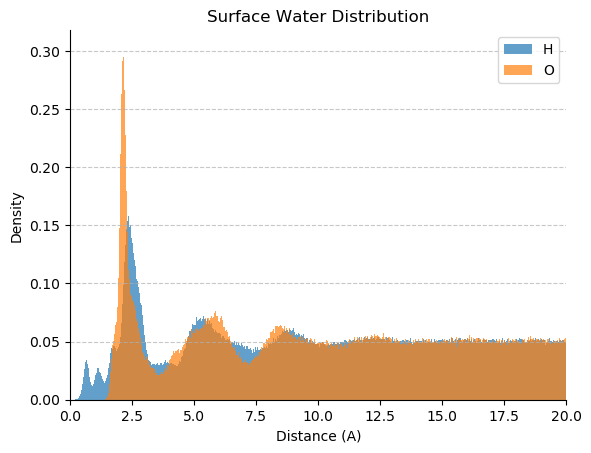

In [42]:

bins = np.linspace(0, 20, 1000) 
plt.hist(zH_t, bins, density=True, linewidth=0.5, alpha=0.7, label='H')
plt.hist(zO_t, bins, density=True, linewidth=0.5, alpha=0.7, label='O')

# Add title and labels
plt.title('Surface Water Distribution', fontsize=12)
plt.xlabel('Distance (A)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Customize grid and axes
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend()
plt.xlim(0,20)

In [166]:
max_distance=21 #less then 26 surface down (zSd) and then max distance from the upper surface (lattice_z - Sz_u)  

H_u, H_d=surface_up_down_split(H, z_u, z_d,  max_distance)
O_u, O_d=surface_up_down_split(O, z_u, z_d,  max_distance)



H_u, H_extra_u=cut_largest_z_atom(H_u)  #cut_largest_z_atom is bastard a bastard function, it acts on the variable that you give no matter if you assign to a new variable
H_d, H_extra_d=cut_largest_z_atom(H_d)

O_u, O_extra_u=cut_largest_z_atom(O_u)  
O_d, O_extra_d=cut_largest_z_atom(O_d)


Total atom per t slice 1585
Max atom removed 40
Total atom removed and appended in atom_left 11690
Distance of max height covered in every t 20.468552664528147
Total atom per t slice 1584
Max atom removed 50
Total atom removed and appended in atom_left 12992
Distance of max height covered in every t 20.46795933438535
Total atom per t slice 790
Max atom removed 25
Total atom removed and appended in atom_left 7109
Distance of max height covered in every t 20.423252664528142
Total atom per t slice 790
Max atom removed 27
Total atom removed and appended in atom_left 7357
Distance of max height covered in every t 20.383719334385347


In [167]:
def up_down_z_all_t_extractor(H_u, H_d ):
    zH_ud=[]
    for t in range(len(H_u)):
    
        for atom in H_u[t]:
    
            zH_ud.append(atom[2])
            
    for t in range(len(H_d)):
        for atom in H_d[t]:
    
            zH_ud.append(atom[2])

    print(len(zH_ud))
    return zH_ud

In [168]:
len(H_u)

604

In [169]:
zH_ud= up_down_z_all_t_extractor(H_u, H_d)
zO_ud= up_down_z_all_t_extractor(O_u, O_d)

1914076
954320


(0, 20)

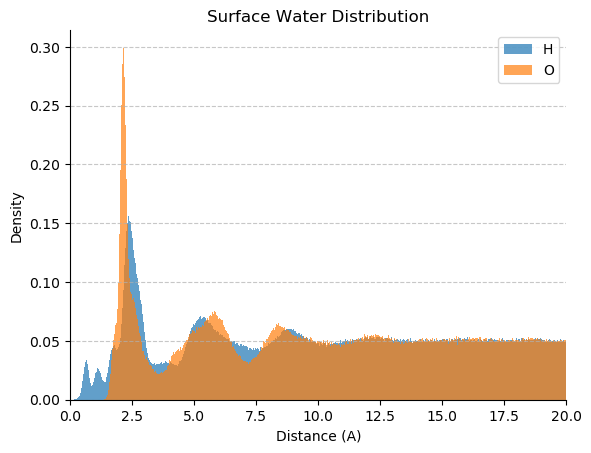

In [170]:
bins = np.linspace(0, 20, 500) 

plt.hist(zH_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='H')
plt.hist(zO_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='O')

# Add title and labels
plt.title('Surface Water Distribution', fontsize=12)
plt.xlabel('Distance (A)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Customize grid and axes
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend()
plt.xlim(0,20)

In [171]:
#oct and tet analysis based on oxygens surface layer: OS_u or OS_d as input, box xy diagonal, and  cluster parm epsilon =1
#output diagonal O raws displacment to separate (Fe) oct and tet zones
def get_diagonal_O_raws(OS_u, control, diag_lenght,  epsilon):
    diagonal_projection=[]

    
    for atom in OS_u[0]:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
        #print(theta)
        if control == 'u':
            diagonal_projection.append(r*np.cos(theta - (np.pi/4)  )   )
        elif control == 'd':
            diagonal_projection.append(r*np.sin(theta - (np.pi/4)  )   )
        else:
            print("control must be 'u' or 'd'")
            return

    #clusterization of diagonal projection of O position in raws
    displacement=[]
    
    displacement.append([diagonal_projection[0]])

    for i, proj in enumerate(diagonal_projection[1:]):
        copy=displacement
     
        for j in range(len(copy)):
            #print(j)
            if np.abs(proj-displacement[j][0])<epsilon:
                displacement[j].append(proj)
                #print("existing")
                break
            elif j==len(copy)-1:      #last round and no match found create new entry
                #print("new")
                displacement.append([proj])


    #average over the O diagonal raws
    mean_displacement=[]   
    for i in displacement:
        mean_displacement.append(np.mean(i))
    mean_displacement=list(np.sort(mean_displacement))
   
    #calculate averages of tet and oct
    len_oct_tmp=[]
    len_tet_tmp=[]
    for i in range(int(len(mean_displacement)/2-2)):
        len_oct_tmp.append(mean_displacement[2*i+1]-mean_displacement[2*i])
        len_tet_tmp.append(mean_displacement[2*i+2]-mean_displacement[2*i+1])
        if np.mean(len_oct_tmp) <3:
             len_oct=len_oct_tmp
             len_tet= len_tet_tmp
        else:
            len_oct=len_tet_tmp
            len_tet= len_oct_tmp
    print("Oct spacing=",np.mean(len_oct))
    print("Tet spacing=",np.mean(len_tet))

    #if control == 'u':
    #    print(f"Boundaries extra (tet)=",  mean_displacement[0] ,  diag_lenght-mean_displacement[-1])  
    #else:
    #    print(f"Boundaries extra (tet)=", diag_lenght/2 -np.abs(mean_displacement[0]) , np.abs(diag_lenght/2-mean_displacement[-1])  )
    
    #insert boundaries
    if control == 'u':
        mean_displacement.insert(0,0)
        mean_displacement.append(diag_lenght)
    else:
        mean_displacement.insert(0,-diag_lenght/2)
        mean_displacement.append(diag_lenght/2)
    print(mean_displacement)
    return list(mean_displacement)

In [172]:
#distance between O ~ 2.7A inside(oct), outside O (tet) 3.2  == cluster parameter epsilon =1

epsilon=1 #sensibility inside raws: within raw O clusterization threeshold
diag_lenght=47.5 #simulation box xy diagonal lenght to add boundaries 

control_u='u'
diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, epsilon ) #OS_u or OS_d, control u or d accordingly,diag_lenght and epsilon=1


control_d='d'
diag_raw_d=get_diagonal_O_raws(OS_d, control_d, diag_lenght, epsilon ) #OS_u or OS_d, control u or d accordingly,diag_lenght and epsilon=1


Oct spacing= 2.7289199430188136
Tet spacing= 3.2038593933078374
[0, 4.04659886756922, 6.739183708581663, 10.03374976562165, 12.735593286050253, 15.942936484194012, 18.64599982274573, 21.876610512629373, 24.639284724811034, 27.775761971763135, 30.56019577468278, 33.71049554920248, 36.43251901328267, 39.629787766487034, 42.422871337286914, 45.60287195363907, 47.5]
Oct spacing= 2.7076048025737474
Tet spacing= 3.2110275898030602
[-23.75, -20.247076369393433, -17.58865539251402, -14.432628053066708, -11.69428662687151, -8.441491781201632, -5.719727827452883, -2.522729523736138, 0.17454356369330337, 3.3857661642960664, 6.107990732912003, 9.346085592490606, 12.12450630244798, 15.294326525694686, 17.998747273564014, 21.121951305484306, 23.75]


In [173]:
#oct/tet regions atomic separation
#inside O raws = oct, outside = tet: 
#if diagonal projection in (diag_raw[2n],diag_raw[2n+1]) then tet region  even!
#if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
def tet_oct_split(O_u, diag_raw , control ):
   
    
    O_tet_u=[]
    O_oct_u=[]

    tmp_oct=[]
    tmp_tet=[]
    
    for t in range(len(O_u)):
        if tmp_oct != []:
            O_oct_u.append(tmp_oct)
            tmp_oct=[]
        if tmp_tet != []:
            O_tet_u.append(tmp_tet)
            tmp_tet=[]

        for atom in O_u[t]:
            r=np.sqrt(atom[0]**2+atom[1]**2)
            theta=np.arctan(atom[1]/atom[0])
       
            if control == 'u':
                diagonal_projection=(r*np.cos(theta - (np.pi/4)  )) #up cos raws              
            elif control == 'd':
                diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  ////   
                
            else:  
                print("control must be 'u' or 'd'")
                return   
            
            if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                    print("OUT of bounds: diag, atom =" , diagonal_projection, atom)
            if diag_raw[2]-diag_raw[1]<3:               #check if the first 2 oct raws are oct or tet
                for n in range(len(diag_raw)-1):  
                    if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                        if n % 2 ==0:
                            tmp_tet.append([atom[0], atom[1], atom[2]]) #n even ==> outside O raws == tet region
                        else:
                            tmp_oct.append([atom[0], atom[1], atom[2]]) #n odd ==> inside O raws == oct region
                        break
            else:
                for n in range(len(diag_raw)-1):  
                    if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                        if n % 2 ==0:
                            tmp_oct.append([atom[0], atom[1], atom[2]]) #n even ==> inside O raws == oct region
                        else:
                            tmp_tet.append([atom[0], atom[1], atom[2]]) #n odd ==> outside O raws == tet region
                    break
                

    O_oct_u.append(tmp_oct)
    O_tet_u.append(tmp_tet)
    
    return O_oct_u,  O_tet_u

In [ ]:
#oct/tet regions atomic separation
#inside O raws = oct, outside = tet: 
#if diagonal projection in (diag_raw[2n],diag_raw[2n+1]) then tet region  even!
#if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
def tet_oct_split(O_u, diag_raw , control ):
   

    O_oct_u=[]
    O_tet_u=[]
    


    for atom in O_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  )) #up cos raws              
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  ////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag, atom =" , diagonal_projection, atom)
        if diag_raw[2]-diag_raw[1]<3:               #check if the first 2 oct raws are oct or tet
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n even ==> outside O raws == tet region
                    else:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n odd ==> inside O raws == oct region
                    break
        else:
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n even ==> inside O raws == oct region
                    else:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n odd ==> outside O raws == tet region
                break
                

    
    return O_oct_u,  O_tet_u

In [174]:

O_oct_u, O_tet_u=tet_oct_split(O_u, diag_raw_u , control_u )
O_oct_d, O_tet_d=tet_oct_split(O_d, diag_raw_d , control_d )


H_oct_u, H_tet_u=tet_oct_split(H_u, diag_raw_u , control_u )
H_oct_d, H_tet_d=tet_oct_split(H_d, diag_raw_d , control_d )

In [175]:
zH_tet_ud= up_down_z_all_t_extractor(H_tet_u, H_tet_d)
zH_oct_ud= up_down_z_all_t_extractor(H_oct_u, H_oct_d)
zO_tet_ud= up_down_z_all_t_extractor(O_tet_u, O_tet_d)
zO_oct_ud= up_down_z_all_t_extractor(O_oct_u, O_oct_d)

1050202
863874
507299
447021


(0, 20)

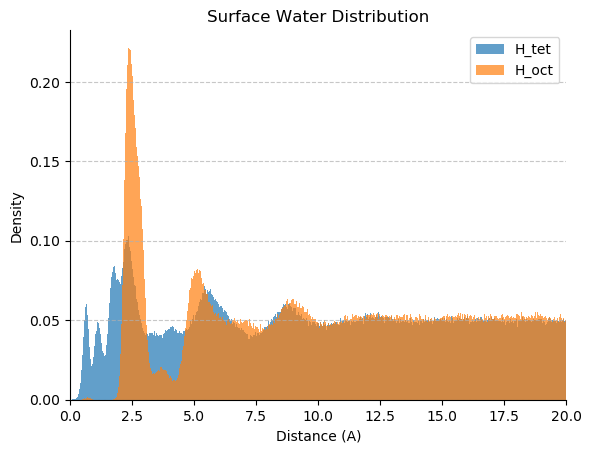

In [176]:
bins = np.linspace(0, 20, 500) 

plt.hist(zH_tet_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='H_tet')
plt.hist(zH_oct_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='H_oct')

# Add title and labels
plt.title('Surface Water Distribution', fontsize=12)
plt.xlabel('Distance (A)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Customize grid and axes
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend()
plt.xlim(0,20)

(0, 20)

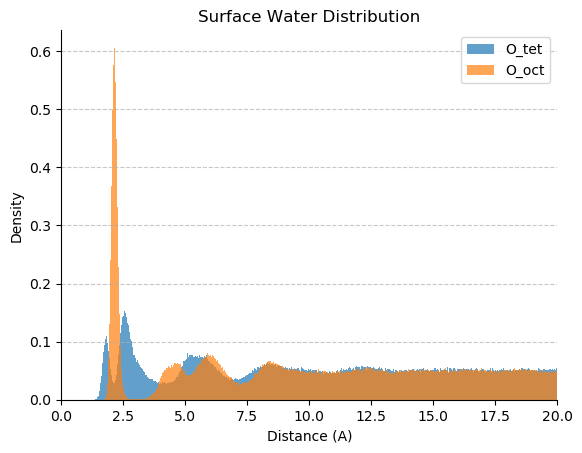

In [177]:

plt.hist(zO_tet_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='O_tet')
plt.hist(zO_oct_ud, bins=bins, density=True, linewidth=0.5, alpha=0.7, label='O_oct')

# Add title and labels
plt.title('Surface Water Distribution', fontsize=12)
plt.xlabel('Distance (A)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Customize grid and axes
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend()
plt.xlim(0,20)

In [160]:
type_name =["H", "O", "OS_u", "OS_d", "FeS_u", "FeS2_u", "FeS2_d", "FeS_d"]
trj_all=[H, O, OS_u, OS_d,  FeS_u, FeS2_u, FeS2_d, FeS_d]

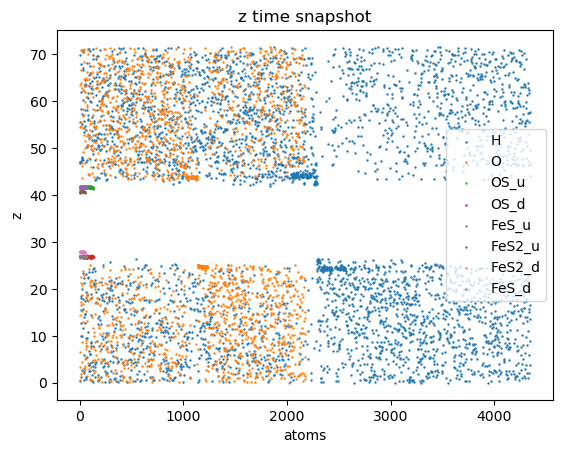

In [161]:
for i, element in enumerate(trj_all[:]):
    plt.scatter(np.arange(len(element[5][:,2])), element[5][:,2], label = type_name[i] , s =0.5)
    plt.title("z time snapshot")
    plt.ylabel("z")
    plt.xlabel("atoms")
    plt.legend()

    

In [2]:
import ase.io as aio

In [8]:
species1_hist = []
species2_hist = []
for mol in aio.iread('./full_coverage/run_1/cut.trj',format='lammps-dump-text'):
    
    
    # get all atoms needed to make histogram of a single snapshot
    
    
    
    # divide into oct and tet
    
    # store distance for each coordination into array
    
    
    
    mols.append(mol)

In [23]:
mol.get_a

array([[12.4875365 , 59.4360011 ,  9.93599383, ..., 33.98583225,
        35.78336347, 34.78579812],
       [43.52813515, 12.10860813, 46.9218329 , ..., 21.45006862,
        23.29003942, 24.15299331],
       [14.28665233, 55.78746944, 16.23699622, ..., 28.38117638,
        28.56822579, 26.87026294],
       ...,
       [33.38773753, 26.78823145, 38.24561724, ..., 13.96212817,
        18.29906628, 11.42650587],
       [42.59565474, 22.37559058, 44.45182012, ..., 22.46222103,
        16.91360303, 26.16463622],
       [45.05557776, 23.60520555, 49.61789838, ..., 23.91232315,
        25.99866462, 22.44395545]])

In [18]:
import numpy as np

def split_by_element(mol, element_ids):
    splitted = []
    for elid in element_ids:
        indices = np.where(mol.get_atomic_numbers()==1)
        splitted.append(mol.get_positions()[indices])

In [21]:
 h_xyz 

array([[17.2566 , 29.4203 , 48.0175 ],
       [ 1.60175, 22.0407 ,  3.23214],
       [13.0478 , 26.4763 , 52.3614 ],
       ...,
       [30.0172 ,  9.14341, 18.0568 ],
       [30.7791 , 30.346  , 10.1558 ],
       [ 3.64858, 10.0049 , 21.0502 ]])

In [15]:
h_xyz

NameError: name 'h_indices' is not defined